# Dispatch simulator: step log and evidence

This notebook shows what the simulator's functions take in and give back, on concrete cases. The code lives in the
five files next to this notebook (`environment.py`, `policies.py`, `scenarios.py`, `measures.py`, `main.py`); the
notebook imports them and redefines nothing. Whole-year results come from the tables that `main.py` writes. The last
cell compares those tables with the tables written before the code was reorganized.

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parents[1]                     # this notebook lives in code/dispatch_simulator/
sys.path.insert(0, str(PROJECT_ROOT / "code" / "dispatch_simulator"))
import environment, measures, policies, scenarios
from environment import TIME_COLUMNS

OUTPUT_DIR = PROJECT_ROOT / "data" / "reports" / "dispatch_simulator"
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
RECORD_COLOR, SIMULATED_COLOR = "#333333", "#E69F00"       # dark grey and orange

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


## 1. The world: the record and every fitted input

`build_world` loads the 2025 record and fits each fixed input once: the repaired runs, the engines and the agency
line, the road network and the travel model, the drive home, the travel spread, the quint penalty and the fire-call
map. Every step prints its tables.

In [2]:
world = environment.build_world(verbose=True)

--- 2025 engine dispatches (input) (37194, 32)
   incident_id    call_received_at                      problem call_type protocol determinant_level determinant_code  priority  n_engines_sent  incident_lon  incident_lat jurisdiction  focal engine_id engine_type engine_agency  engine_lon_at_dispatch  engine_lat_at_dispatch from_station  at_home       dispatched_at          enroute_at          arrived_at          cleared_at  turnout_s  travel_s  on_scene_s  arrival_order  staged  cancelled  auto_aid                                qc_note
0  100124-0043 2024-10-01 01:52:55      E06 - BREATHING PROBLEM   Medical      E06              <NA>              E06  Moderate               1    -82.087103     29.602245         ACFR  False       E62           E       non-GFR              -82.086615               29.585837         <NA>     True 2024-10-01 01:53:16 2024-10-01 01:54:18 2024-10-01 02:00:55 2024-10-01 02:03:24         62       397         149              1   False      False     False     

times recorded (1 = present, order dispatched/enroute/arrived/cleared): {'1111': 30475, '1101': 6716, '1110': 2, '1100': 1}
a later time before an earlier one: 2 runs
dispatched before the call: 0 runs
engine dispatched again before its previous run cleared: 3 runs
--- timelines repaired: 5 runs (median on-scene 730 s, median cancelled 333 s)
           recorded                                          repaired                                    
      dispatched_at  enroute_at  arrived_at  cleared_at dispatched_at  enroute_at  arrived_at  cleared_at
7291     14208332.0  14208363.0  14210219.0  14210116.0    14208332.0  14208363.0  14210219.0  14210219.0
13763    26729464.0  26729520.0  26729963.0         NaN    26729464.0  26729520.0  26729963.0  26730693.0
13764    26730314.0  26730364.0         NaN         NaN    26730314.0  26730364.0         NaN  26730647.0
14718    28632548.0  28632547.0  28632743.0  28633144.0    28632548.0  28632548.0  28632743.0  28633144.0
33796    26729154.0

road network: 15,085 nodes, 36,242 edges; largest strongly connected part kept: 15,048 nodes, 36,197 edges
edge speed_kph (free flow, OSM): median 40, P10 40, P90 65; edge travel_time missing: 0



--- calls snapped to the network (rows: runs) (37194, 2)
        node      snap_m
0  666957816   74.815862
1   84910563   29.307305
2   84882940  113.935883
3   84826992  200.208110
4   84853411   23.342101

--- engine home stations snapped to the network (29, 3)
  engine_id        node     snap_m
0        E1    84918009  35.035384
1        Q1    84855238  36.471538
2        E2   618869091  51.480986
3        Q2   618869091  51.433319
4        E3  5971432219  72.511009

call snap distance (m): median 66, P90 216, P99 705; over 500 m: 778 runs; no coordinates: 4 runs
engine snap distance (m): median 51, max 201; distinct home nodes: 28 for 29 engines



--- network free-flow seconds, home station -> call (rows: runs) (37194, 29)
engine_id      E1      Q1      E2      Q2      E3      E4      E5      E7      Q8      E9      Q9     E21     E22     Q23     E24     E25     E28     Q28     E29     E40     E42     E60     E61     E62     E63     E64     E80     E81     E82
0          1098.0  1094.0  1349.0  1349.0  1029.0  1451.0  1363.0  1736.0  1603.0  1560.0  1554.0  2196.0  2202.0  1823.0  2100.0  1959.0  2535.0  2532.0  2670.0   827.0   605.0   805.0   811.0   108.0   957.0  1070.0  1901.0  1808.0  2206.0
1          1136.0  1131.0  1387.0  1387.0  1066.0  1488.0  1400.0  1773.0  1640.0  1598.0  1592.0  2234.0  2239.0  1860.0  2137.0  1996.0  2572.0  2569.0  2707.0   921.0   699.0   842.0   848.0   141.0   990.0  1107.0  1939.0  1845.0  2243.0
2          1581.0  1586.0  1333.0  1333.0  1645.0  1210.0  1323.0  1165.0  1229.0  1241.0  1235.0   471.0   977.0  1102.0  1130.0   711.0   850.0   856.0    59.0  2147.0  2559.0  1911.0  2483.0  27

runs sent within 60 min of clearing a call they reached, in the scene -> home corridor: 7,515, 78% at home (fit 5,558 before 2025-07-01, test 1,957); median actual share of the way home 0.99
fitted (Optimization terminated successfully.): dwell 0 s near the scene, then 1.18 x the modeled drive home
                       test runs  mean |share error|  median predicted share
no dwell, no slowdown     1957.0               0.072                     1.0
AVL-fitted                1957.0               0.071                     1.0
median share by minutes since clear (test runs):
           actual_share  no dwell, no slowdown  AVL-fitted  share at home  runs
elapsed_s                                                                      
(0, 1]             0.05                   0.07        0.06           0.01   106
(1, 2]             0.29                   0.28        0.24           0.10    62
(2, 4]             0.48                   0.54        0.45           0.29    94
(4, 8]             0

travel spread fitted on 19,349 runs before 2025-07-01 that left from home, tested on 6,410 later runs (held out from the ratios)
--- ratio recorded / modeled travel by area and bin of modeled travel; held-out shares outside the bin's P10-P90 (about 0.10 each if calibrated)
                 modeled from (min)  modeled to (min)  fitting runs  ratio P1  ratio P10  ratio P50  ratio P90  ratio P99  held-out runs  held-out below P10  held-out above P90
inside_city bin                                                                                                                                                                 
False       0                 2.474             3.571           992     0.020      0.280      1.097      1.848      6.167            300               0.127               0.110
            1                 3.571             4.386           991     0.604      0.824      1.167      1.751      4.685            266               0.060               0.135
            2     

--- readiness cells (training fire calls per cell) (425, 12)
   cell_x  cell_y  calls_aid  calls_other  gfr_share        lon        lat  cell_gfr  weight_aid  weight_own      node       snap_m
0     340    3271          0            1        0.0 -82.646858  29.558544     False    0.000000    0.001042  84934325   178.074692
1     340    3280          1            0        0.0 -82.647244  29.646569     False    0.001042    0.000000  84804790  1055.957890
2     341    3268          1            0        0.0 -82.634273  29.537499     False    0.001042    0.000000  84798500   418.168177
3     341    3276          0            1        0.0 -82.639706  29.609180     False    0.000000    0.001042  84885410     0.000000
4     341    3300          0            1        0.0 -82.644962  29.823081     False    0.000000    0.001042  84774663   200.933956

training fire calls: 960 in 425 cells of 1000 m; with automatic aid 436, own agency only 524; cells mostly GFR 105; snap distance median 99 m, P90

### 1.1 One run, in the record and as the simulator replays it (seconds since 1 October 2024)

In [3]:
record = world["record"]
print(world["dispatches"].loc[0, ["incident_id", "protocol", "priority", "engine_id", "call_received_at"] + TIME_COLUMNS].to_string())
print()
print(record["runs"].loc[0].to_string())

incident_id                 100124-0043
protocol                            E06
priority                       Moderate
engine_id                           E62
call_received_at    2024-10-01 01:52:55
dispatched_at       2024-10-01 01:53:16
enroute_at          2024-10-01 01:54:18
arrived_at          2024-10-01 02:00:55
cleared_at          2024-10-01 02:03:24

incident_id         100124-0043
engine_id                   E62
call_received_at         6775.0
dispatched_at            6796.0
enroute_at               6858.0
arrived_at               7255.0
cleared_at               7404.0


### 1.2 Road travel for that run

The network gives free-flow seconds from each station to the call; the travel model turns them into modeled travel;
the agency line removes engines across the line (NaN).

In [4]:
travel_model_parameters = world["travel_model"](np.array([0.0, 1.0]))
print(f"travel model: travel = {travel_model_parameters[0]:.1f} s + {travel_model_parameters[1] - travel_model_parameters[0]:.3f} x network seconds")
print("travel_model([60, 300, 600]) ->", world["travel_model"](np.array([60.0, 300.0, 600.0])).round(1))
pd.DataFrame({"network seconds": world["network_seconds"].loc[0], "modeled travel s": record["travel"].loc[0]}).round(1).sort_values("modeled travel s")

travel model: travel = 148.4 s + 1.002 x network seconds
travel_model([60, 300, 600]) -> [208.6 449.2 749.9]


,network seconds,modeled travel s
engine_id,,
E62,108.4,257.1
E42,604.9,754.8
E60,805.2,955.6
E61,811.2,961.6
E40,827.0,977.4
E63,956.9,1107.6
E3,1029.1,1180.0
E64,1069.8,1220.8
E1,1098.4,1249.5


### 1.3 The drive home after a call

In [5]:
print(f"fitted dwell {world['dwell_s']:.1f} s, slowdown {world['slowdown']:.3f}")
for elapsed in [60.0, 300.0, 600.0, 800.0]:
    print(f"return_progress({elapsed:.0f} s since clearing, 600 s modeled drive) ->",
          environment.return_progress(elapsed, 600.0, world["dwell_s"], world["slowdown"]))
world["fits"]["return_progress"]

fitted dwell 0.0 s, slowdown 1.183
return_progress(60 s since clearing, 600 s modeled drive) -> 0.08451088388248178
return_progress(300 s since clearing, 600 s modeled drive) -> 0.4225544194124097
return_progress(600 s since clearing, 600 s modeled drive) -> 0.8451088388248196
return_progress(800 s since clearing, 600 s modeled drive) -> None


,test runs,mean |share error|,median predicted share
"no dwell, no slowdown",1957.0,0.072399,1.0
AVL-fitted,1957.0,0.071031,1.0


### 1.4 Real travel around modeled travel

In [6]:
toy = {True: (np.array([300.0]), [np.array([0.5, 1.0, 2.0]), np.array([0.9, 1.0, 1.1])])}
print("toy:", environment.draw_travel_ratio(toy, True, 200.0, 0.5), environment.draw_travel_ratio(toy, True, 200.0, 0.99),
      environment.draw_travel_ratio(toy, True, 400.0, 0.99))
row, engine = 0, "E62"
modeled = record["travel"].at[row, engine]
quantile = record["spread_quantile"][row]
ratio = environment.draw_travel_ratio(world["travel_spread"], bool(record["inside_city"][row]), modeled, quantile)
print(f"run {row}, {engine}: modeled {modeled:.2f} s, quantile {quantile:.4f}, ratio {ratio:.4f}, travel taken {modeled * ratio:.2f} s")
world["fits"]["travel_spread"].round(3)

toy: 1.0 2.0 1.1
run 0, E62: modeled 257.05 s, quantile 0.8001, ratio 1.5270, travel taken 392.51 s


modeled from (min)  modeled to (min)  fitting runs  ratio P1  ratio P10  ratio P50  ratio P90  ratio P99  held-out runs  held-out below P10  held-out above P90
inside_city bin                                                                                                                                                                 
False       0                 2.474             3.571           992     0.020      0.280      1.097      1.848      6.167            300               0.127               0.110
            1                 3.571             4.386           991     0.604      0.824      1.167      1.751      4.685            266               0.060               0.135
            2                 4.386             5.037           999     0.644      0.879      1.221      1.782      4.049            300               0.120               0.100
            3                 5.037             5.926           974     0.664      0.849      1.114      1.616      3.594            344               0.076               0.084
            4                 5.926             6.977           993     0.679      0.828      1.071      1.514      2.885            331               0.094               0.106
            5                 6.977             8.194           984     0.654      0.828      1.057      1.446      2.986            290               0.107               0.121
            6                 8.194            10.515           995     0.606      0.818      1.046      1.467      2.776            318               0.091               0.097
            7                10.515            30.979           983     0.498      0.752      0.987      1.369      2.548            276               0.076               0.083
True        0                 2.474             3.493          1430     0.035      0.523      0.902      1.541      3.717            514               0.130               0.068
            1                 3.493             4.078          1441     0.503      0.681      0.968      1.440      3.096            466               0.116               0.155
            2                 4.078             4.570          1443     0.514      0.677      0.910      1.401      3.144            515               0.105               0.105
            3                 4.570             5.004          1408     0.534      0.686      0.937      1.349      2.768            511               0.070               0.123
            4                 5.004             5.434          1436     0.548      0.719      0.972      1.411      2.714            499               0.094               0.086
            5                 5.434             5.963          1420     0.595      0.733      0.958      1.355      2.578            503               0.089               0.095
            6                 5.963             6.481          1430     0.589      0.734      0.940      1.298      2.148            525               0.082               0.145
            7                 6.481            20.378          1430     0.503      0.728      0.941      1.272      2.513            452               0.073               0.095

### 1.5 The quint penalty, the call fates, the run attributes and the opportunity cost

In [7]:
print("quint penalty by call type (s):", world["quint_penalty_by_type"])
print("call fates of incident 100124-0344 (arrivals, release moments, on-scene seconds):", record["fates"]["100124-0344"])
print("runs per attribute:", {name: int(record[name].sum()) for name in ["inside_city", "brush", "low_acuity"]},
      "; wait ranks:", record["wait_rank"].value_counts().sort_index().to_dict())
print("opportunity cost of sending E1 or E3 when E1, E3 and E5 are idle (minutes):",
      world["opportunity_cost"](["E1", "E3", "E5"], ["E1", "E3"]).round(3).to_dict())

quint penalty by call type (s): {'F56 elevator': -260.0, 'F82 brush fire': 260.0, 'all other calls': 10.0}
call fates of incident 100124-0344 (arrivals, release moments, on-scene seconds): (1, [38904.0], [121.0])
runs per attribute: {'inside_city': 21015, 'brush': 633, 'low_acuity': 7943} ; wait ranks: {0.0: 10409, 1.0: 9145, 2.0: 12740, 3.0: 4900}
opportunity cost of sending E1 or E3 when E1, E3 and E5 are idle (minutes): {'E1': nan, 'E3': nan}


## 2. One day under the protocol, decision by decision

The first day's calls are simulated with the protocol. A thin wrapper records what the policy saw at each decision:
the available engines and their modeled travel from where each engine was at that moment.

In [8]:
day_rows = record["runs"].index[record["runs"]["call_received_at"] < 86400]
day = {**record, "dispatches": world["dispatches"].loc[day_rows], "runs": record["runs"].loc[day_rows],
       "fates": environment.call_fates(record["runs"].loc[day_rows])}
decisions = {}

def recording_protocol(world_, scenario_, run, available_engines, travel_s, context=None):
    choice = policies.closest_engine(world_, scenario_, run, available_engines, travel_s)
    decisions[run.name] = (list(available_engines), travel_s.copy(), choice)
    return choice

day_report = {}
day_run = environment.simulate(world, day, recording_protocol, day_report)
pd.concat({"record (repaired)": day["runs"][TIME_COLUMNS + ["engine_id"]], "simulated": day_run}, axis=1).head(8)

--- simulated CAD times (seconds since day zero) and engine used (109, 5)
   dispatched_at  enroute_at    arrived_at    cleared_at engine_id
0         6796.0      6858.0   7250.514401   7399.514401       E62
1        23905.0     23956.0  24425.492028  25179.492028       E62
2        28215.0     28215.0  28412.330196  30267.330196       E29
3        29358.0     29358.0  29361.000000  31955.000000       E60
4        36851.0     36891.0  37355.456439  38100.456439        E3



record (repaired)                                                simulated                                                 
      dispatched_at enroute_at arrived_at cleared_at engine_id dispatched_at enroute_at    arrived_at    cleared_at engine_id
0            6796.0     6858.0     7255.0     7404.0       E62        6796.0     6858.0   7250.514401   7399.514401       E62
1           23905.0    23956.0    24342.0    25096.0       E62       23905.0    23956.0  24425.492028  25179.492028       E62
2           28215.0    28215.0    28388.0    30243.0       E29       28215.0    28215.0  28412.330196  30267.330196       E29
3           29358.0    29358.0    29358.0    31952.0       E60       29358.0    29358.0  29361.000000  31955.000000       E60
4           36851.0    36891.0    37848.0    38593.0       E40       36851.0    36891.0  37355.456439  38100.456439        E3
5           38751.0    38795.0    39025.0    39487.0       E81       38751.0    38795.0  39349.879501  39811.879501       E80
6           39448.0    39517.0    39780.0    40742.0       E21       39448.0    39517.0  39877.039304  40839.039304       E21
7           39529.0    39529.0        NaN    39649.0       E29       39529.0    39529.0           NaN  39649.000000       E29

### 2.1 One low-acuity decision under both policies

For a low-acuity run where the opportunity-cost rule would send another engine, the table shows each available engine's
modeled travel from where it was, the ranking with the quint penalty, and the opportunity cost of sending it.

In [9]:
for row, (available, travel_s, protocol_choice) in decisions.items():
    if day["low_acuity"][row]:
        protocol_engine, rule_engine, costs = policies.opportunity_cost_choice(world, day, day["runs"].loc[row], available, travel_s)
        if rule_engine != protocol_engine:
            break
run = day["runs"].loc[row]
print(f"run {row}: call {run['incident_id']} ({world['dispatches'].at[row, 'protocol']}, {world['dispatches'].at[row, 'priority']}), "
      f"at {environment.DAY_ZERO + pd.Timedelta(seconds=day_run.at[row, 'dispatched_at'])}")
penalty = world["quint_indicator"] * day["quint_penalty"][row]
view = pd.DataFrame({"modeled travel s": travel_s[available], "ranking s": (travel_s + penalty)[available],
                     "opportunity cost min": costs}).dropna(subset=["modeled travel s"]).sort_values("ranking s")
print(f"protocol sends {protocol_engine}; the opportunity-cost rule sends {rule_engine}")
view.round(3)

run 16207: call 100124-0034 (E12, Low), at 2024-10-01 01:38:18
protocol sends E3; the opportunity-cost rule sends E1


,modeled travel s,ranking s,opportunity cost min
E3,235.619,235.619,0.235
E1,287.317,287.317,0.090
E2,542.173,542.173,NaN
E5,557.624,557.624,NaN
E4,645.602,645.602,NaN
E9,753.666,753.666,NaN
Q9,747.740,757.740,NaN
Q8,798.389,808.389,NaN
E7,931.555,931.555,NaN


### 2.2 Where engines were when sent, the travel drawn, and the call fates

In [10]:
origins = measures.describe_engine_origins(world, day, day_report["dispatches"])
measures.describe_travel_draws(origins[~origins["run"].map(day["brush"]).astype(bool).to_numpy()], world["travel_spread"], day["inside_city"])
measures.describe_call_fates(day["runs"], day_run, day_report["dispatches"], day["fates"])
measures.check_run_states(day["runs"], day_run, day["dispatches"], day_report)

--- where engines were when the simulation sent them
                                    dispatches  share
origin                                               
at station                                  99  0.917
driving home from a call                     7  0.065
driving home after a cancelled run           2  0.019
2025 record, AVL position at assignment: {'at its station': 0.78, 'away from its station': 0.22}
share of the way home by minutes since clearing (engines on the way home):
                     size  median
minutes since clear              
(0, 2]                  3    0.09
(2, 4]                  4    0.41
(4, 8]                  2    0.83

examples, at station:
  run                time engine_id     origin  minutes since clear  share of way home  modeled min  taken min  from home min
16205 2024-10-01 00:07:07        E9 at station                  NaN                NaN         5.72       4.61           5.72
16206 2024-10-01 00:45:34        E9 at station              

runs never served                                           0.0
runs sent while their engine was still on an earlier run    0.0
calls whose number of arrivals differs from 2025            0.0
runs with times out of order                                0.0
runs served without a clear                                 0.0
runs that kept their 2025 times                             0.0
runs of calls without a location                            0.0
cancelled requests that never got an engine                 1.0
calls whose first arrival is the recorded second (share)    0.0
runs that waited for an engine                              0.0
wait seconds: median                                        NaN
wait seconds: max                                           NaN
dtype: float64

## 3. The whole year: the simulator against the record

These tables come from `main.py`'s run. The simulator passes its check when no state check is violated, only calls
without a location keep their recorded times, and the first-on-scene curve RMSE is at most 0.03.

In [11]:
states = pd.read_csv(OUTPUT_DIR / "simulator_check_states.csv", index_col=0)
strata = pd.read_csv(OUTPUT_DIR / "simulator_check_strata.csv", index_col=0)
print(states.to_string(), "\n")
print(strata.round(4).to_string(), "\n")
pd.read_csv(OUTPUT_DIR / "simulator_check_matrix.csv", index_col=0).round(3)

                                                              value
runs never served                                          0.000000
runs sent while their engine was still on an earlier run   0.000000
calls whose number of arrivals differs from 2025           0.000000
runs with times out of order                               0.000000
runs served without a clear                                0.000000
runs that kept their 2025 times                            4.000000
runs of calls without a location                           4.000000
cancelled requests that never got an engine               23.000000
calls whose first arrival is the recorded second (share)   0.000392
runs that waited for an engine                             0.000000
wait seconds: median                                            NaN
wait seconds: max                                               NaN 

                                     calls    rmse  max_abs_difference
all calls                          33156.0 

,2025 record,protocol run
travel estimate: test mean |error| (min),NaN,1.547
same engine: all runs,1.000,0.727
same engine: first engine of each call,1.000,0.773
same engine: single-engine calls,1.000,0.807
same engine: multi-engine calls,1.000,0.378
same engine: 2025 engine at home,1.000,0.769
same engine: 2025 engine away from home,1.000,0.498
same engine: 2025 engine from the other agency,1.000,0.492
"curve RMSE: first on scene, all calls",0.000,0.010
"curve RMSE: first on scene, inside city",0.000,0.009


In [12]:
fire = pd.read_csv(OUTPUT_DIR / "simulator_check_fire_arrivals.csv", index_col=[0, 1, 2])
print(fire.round(2).to_string(), "\n")
pd.read_csv(OUTPUT_DIR / "simulator_check_brush_quints.csv", index_col=0).round(3)

                                        calls reached in both  mean error s  interval low s  interval high s  mean within m  interval contains 0 interval vs +-m  P90 2025 min  P90 simulated min
version      period     calls                                                                                                                                                                    
protocol run whole year all fire calls                   1537        -23.54          -40.78            -5.83          False                False    undetermined         15.87              14.84
                        F67                               381        -32.48          -58.51            -5.99          False                False    undetermined         15.97              14.60
                        F69                               585         -0.24          -12.14            10.97           True                 True    undetermined         12.14              11.62
                        F71   

,calls,2025,protocol run,protocol run within 5%
inside city,88,0.045,0.034,True
outside city,91,0.099,0.132,True
all,179,0.073,0.084,True


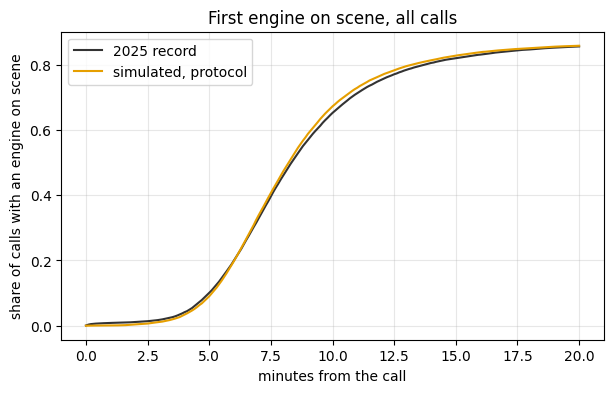

In [13]:
simulated_curves = pd.read_csv(OUTPUT_DIR / "simulator_check_curves.csv")
record_curves = measures.response_curves(world["dispatches"], verbose=False)
fig, ax = plt.subplots(figsize=(7, 4))
for curves, label, color in [(record_curves, "2025 record", RECORD_COLOR), (simulated_curves, "simulated, protocol", SIMULATED_COLOR)]:
    part = curves.query("curve == 'stages' and series == 'first_on_scene'")
    ax.plot(part["minute"], part["share"], label=label, color=color)
ax.set(xlabel="minutes from the call", ylabel="share of calls with an engine on scene", title="First engine on scene, all calls")
ax.legend(); ax.grid(alpha=0.3); plt.show()

## 4. First-due coverage and fire readiness

In [14]:
summary = pd.read_csv(OUTPUT_DIR / "first_due_summary.csv", index_col=[0, 1])
print(summary.xs("all fire calls", level=1).round(3).to_string(), "\n")
print(pd.read_csv(OUTPUT_DIR / "first_due_by_station.csv", index_col=0, header=[0, 1]).head(6).to_string(), "\n")
readiness = pd.read_csv(OUTPUT_DIR / "readiness_summary.csv", index_col=0, header=[0, 1])
readiness.loc[["year, hour-weighted", "year, time-weighted"]].round(3)

              fire calls  no free first-due engine  interval low  interval high  held by medical  held by Fire category  first on scene min, station free: P50  station free: P90  station committed: P50  station committed: P90  extra modeled min when committed: P50
version                                                                                                                                                                                                                                                                 
2025 record       1702.0                     0.071         0.059          0.084            0.587                  0.347                                  8.300             15.847                   9.575                  16.235                                  1.820
protocol run      1702.0                     0.074         0.063          0.085            0.571                  0.349                                  8.177             14.667                   9.887    

2025 record                     protocol run                    
                          R_min R_full_min loss_min        R_min R_full_min loss_min
year, hour-weighted       6.221      6.013    0.208        6.224      6.013    0.211
year, time-weighted       6.194      6.013    0.181        6.196      6.013    0.183

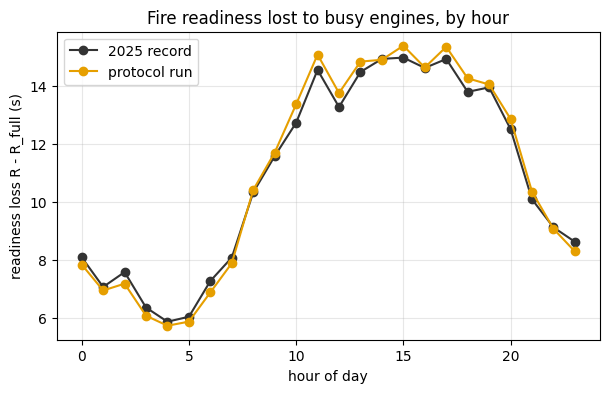

In [15]:
hours = [f"hour {h:02d}" for h in range(24)]
fig, ax = plt.subplots(figsize=(7, 4))
for version, color in [("2025 record", RECORD_COLOR), ("protocol run", SIMULATED_COLOR)]:
    ax.plot(range(24), readiness.loc[hours, (version, "loss_min")] * 60, marker="o", label=version, color=color)
ax.set(xlabel="hour of day", ylabel="readiness loss R - R_full (s)", title="Fire readiness lost to busy engines, by hour")
ax.legend(); ax.grid(alpha=0.3); plt.show()

## 5. The opportunity-cost rule against the protocol

In [16]:
census = pd.read_csv(OUTPUT_DIR / "oc_census.csv", index_col=0)
switched = census["rule_engine_60"] != census["protocol_engine"]
print(f"low-acuity decisions {len(census):,}; with two or more engines within 60 s {(census['choices_60'] >= 2).mean():.3f}; "
      f"rule sends another engine {switched.mean():.3f} ({switched.sum() / 365:.2f} a day)\n")
print(pd.read_csv(OUTPUT_DIR / "oc_over_seeds.csv", index_col=0).round(2).to_string(), "\n")
branches = pd.read_csv(OUTPUT_DIR / "oc_branches.csv", index_col=0)
used = branches[branches["counted"]]
print(f"paired branches: {len(branches)} tried, {len(used)} counted; mean readiness gained over 2 h by the rule's engine {used['benefit_s'].mean():.2f} s")

low-acuity decisions 7,932; with two or more engines within 60 s 0.386; rule sends another engine 0.125 (2.71 a day)

                                                    mean difference s  lowest s  highest s                                                 classes over seeds
outcome                                                                                                                                                      
fire calls, whole year                                           0.22      0.07       0.39                             {'practical equivalence': np.int64(5)}
fire calls, Jul-Sep                                              0.29     -0.33       1.10                             {'practical equivalence': np.int64(5)}
fire calls, first-due station committed (protocol)              -4.23     -5.41      -3.70  {'unresolved': np.int64(3), 'practical equivalence': np.int64(2)}
fire calls, hotspot first-due stations                          -0.02     -0.57       0.56  

## 6. Synthetic scenarios

The generator copies real calls from October to March. A one-week scenario shows each step on concrete cases; the
whole-period results come from `main.py`'s run.

In [17]:
generator = scenarios.fit_generator(world, verbose=False)
week = range(7)
calls, day_factors = scenarios.generate_calls(generator["pool"], generator["counts"], generator["dispersion"], week, 101, verbose=True)

--- generated calls (seed 101) (612, 7)
     incident_id  received_s source_incident   fire  large_fire     kind  location
0  syn101-000000      1873.0     100424-0016  False       False  nominal        -1
1  syn101-000001      4507.0     100424-0030  False       False  nominal        -1
2  syn101-000002      4849.0     100424-0033  False       False  nominal        -1
3  syn101-000003      5880.0     100424-0040  False       False  nominal        -1
4  syn101-000004      6186.0     100424-0042  False       False  nominal        -1

the first week's copied days (other calls) and fire day factors:
 day   weekday  copied day copied weekday  other calls copied  expected other calls  fire day factor
   0   Tuesday           3         Friday                  74                84.545            0.474
   1 Wednesday          13         Monday                  82                86.417            1.123
   2  Thursday           0        Tuesday                  88                87.538          

In [18]:
surged, surges = scenarios.add_short_surges(calls, generator["pool"], generator["locations"], week, 12, 101, verbose=True)
outages = scenarios.add_outages(world["engines"], range(2), 2, 101, verbose=True)
closed = scenarios.close_station(world["engines"], "GFR_03", week, verbose=True)
with_fire = scenarios.add_large_fires(calls, generator["pool"], week, 101, verbose=True)

--- short surges (12 extra calls each) (7, 10)
   day  start_s   end_s first_due_station  centre_block  cell_x  cell_y  focal  extra_calls  usual_other_calls_in_disk
0    0    69643   76843             CO_16          1198     363    3285  False           12                   0.233516
1    1   100290  107490             CO_21          3592     357    3293  False           12                   0.030678
2    2   234262  241462             CO_24          3810     395    3287  False           12                   0.012821
3    3   280592  287792             CO_31           116     386    3264  False           12                   0.003663
4    4   405398  412598             CO_28            47     344    3284  False           12                   0.043956

surges 7 over 7 first-due areas (1-1 each); extra calls 84; usual other calls in the disk over 2 h: median 0.04, so a surge is 282 times the usual (median)
first surge (CO_16, day 0, from second 69,643 of the period):
         incident_id

In [19]:
no_outages = pd.DataFrame(columns=["engine_id", "start_s", "end_s"])
week_scenario = scenarios.build_scenario(world, generator, surged, no_outages, 101, verbose=True)
week_report, week_rule_report = {}, {}
week_protocol = environment.simulate(world, week_scenario, policies.closest_engine, week_report, verbose=False)
week_rule = environment.simulate(world, week_scenario, policies.opportunity_cost_policy, week_rule_report, verbose=False)
first_due, week_census, week_segments = measures.measure_run(world, week_scenario, week_protocol)
print(f"one week with surges of 12 calls: runs {len(week_scenario['runs']):,}; runs where the rule sent another engine "
      f"{int((week_rule['engine_id'] != week_protocol['engine_id']).sum())}")
measures.describe_room(week_scenario["dispatches"], week_census, first_due, week_segments, week).round(3)

--- scenario dispatch table (seed 101) (788, 32)
     incident_id    call_received_at                       problem call_type protocol determinant_level determinant_code  priority  n_engines_sent  incident_lon  incident_lat jurisdiction  focal engine_id engine_type engine_agency  engine_lon_at_dispatch  engine_lat_at_dispatch from_station  at_home       dispatched_at          enroute_at          arrived_at          cleared_at  turnout_s  travel_s  on_scene_s  arrival_order  staged  cancelled  auto_aid qc_note
0  syn101-000000 2024-10-01 00:31:13   E12D - CONVULSIONS/SEIZURES   Medical      E12                 D             E12D      High               1    -82.354765     29.706196          GFR   True        Q8           Q           GFR              -82.370836               29.692203       GFR_08     True 2024-10-01 00:32:08 2024-10-01 00:33:00 2024-10-01 00:39:34 2024-10-01 01:00:12         52       394        1238              1   False      False     False        
1  syn101-000001 20

one week with surges of 12 calls: runs 788; runs where the rule sent another engine 40


other calls per day                                                  95.286
study fire calls per week                                            29.000
low-acuity decisions per day                                         23.714
with a choice (60 s)                                                  0.367
rule would send another engine                                        0.169
  per day                                                             4.000
  readiness saved (s, mean)                                           8.390
  saving infinite (the protocol's engine was the last for a cell)     0.000
fire calls with no free first-due engine                              0.103
fire readiness loss (s, time-weighted)                               13.085
hours with readiness loss over 1 min                                  3.612
dtype: float64

In [20]:
calibration = pd.read_csv(OUTPUT_DIR / "scenario_calibration.csv", index_col=0)
print(f"nominal scenarios inside the record's interval: {int(calibration['inside record interval'].sum())} of {len(calibration)}\n")
print(calibration[["record", "interval low", "interval high", "scenarios", "inside record interval"]].round(3).to_string(), "\n")
pd.read_csv(OUTPUT_DIR / "scenario_room.csv", index_col=0).round(3)

nominal scenarios inside the record's interval: 13 of 13

                                                       record  interval low  interval high  scenarios  inside record interval
other calls per day                                    85.429        83.917         86.830     84.841                    True
study fire calls per week                              36.923        33.808         40.000     38.173                    True
runs per call                                           1.122         1.114          1.131      1.124                    True
share of other calls in the record's 20 busiest cells   0.242         0.235          0.249      0.243                    True
engine busy hours per day                              33.436        32.513         34.405     33.486                    True
low-acuity decisions per day                           21.176        20.516         21.780     21.025                    True
low-acuity decisions with a choice (60 s)               0.36

,nominal,other calls x0.8,other calls x1.1,other calls x1.3,other calls x1.5,"short surges, 6 extra calls","short surges, 12 extra calls","short surges, 24 extra calls",1 engines out each day,2 engines out each day,3 engines out each day,station GFR_03 closed,station CO_21 closed,station CO_16 closed,a large fire each week
other calls per day,85.363,68.242,93.665,111.132,128.401,91.363,97.363,109.363,85.363,85.363,85.363,85.363,85.363,85.363,85.363
study fire calls per week,37.308,37.308,37.308,37.308,37.308,37.308,37.308,37.308,37.308,37.308,37.308,37.308,37.308,37.308,38.308
low-acuity decisions per day,21.187,16.571,23.341,27.500,31.775,22.687,24.126,27.077,21.187,21.187,21.187,21.187,21.187,21.187,21.187
with a choice (60 s),0.348,0.350,0.347,0.345,0.341,0.345,0.342,0.336,0.341,0.335,0.321,0.347,0.356,0.351,0.349
rule would send another engine,0.124,0.130,0.125,0.125,0.124,0.122,0.120,0.122,0.123,0.117,0.116,0.106,0.135,0.120,0.125
per day,2.626,2.154,2.929,3.434,3.929,2.775,2.890,3.313,2.604,2.473,2.467,2.247,2.852,2.533,2.648
"readiness saved (s, mean)",6.079,5.765,6.456,6.397,7.010,6.474,6.660,7.606,6.933,6.766,7.698,7.430,7.202,6.212,6.257
saving infinite (the protocol's engine was the last for a cell),0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
fire calls with no free first-due engine,0.090,0.075,0.098,0.103,0.125,0.092,0.096,0.098,0.124,0.154,0.197,0.208,0.146,0.163,0.093
"fire readiness loss (s, time-weighted)",11.392,9.395,12.325,14.331,16.490,12.298,13.390,16.005,18.207,25.381,33.735,26.989,23.401,22.951,13.417


             surges  usual other calls in the disk  readiness loss without the surge (s)  readiness cost (s)  cost interval low  cost interval high  rule minus protocol (s, first seed)  rule interval low  rule interval high
extra calls                                                                                                                                                                                                                    
6             728.0                           0.25                                 11.37                8.85               8.44                9.21                                -0.43              -0.61               -0.28
12            728.0                           0.25                                 11.37               20.31              19.66               20.91                                -0.54              -0.79               -0.33
24            728.0                           0.25                                 11.37               4

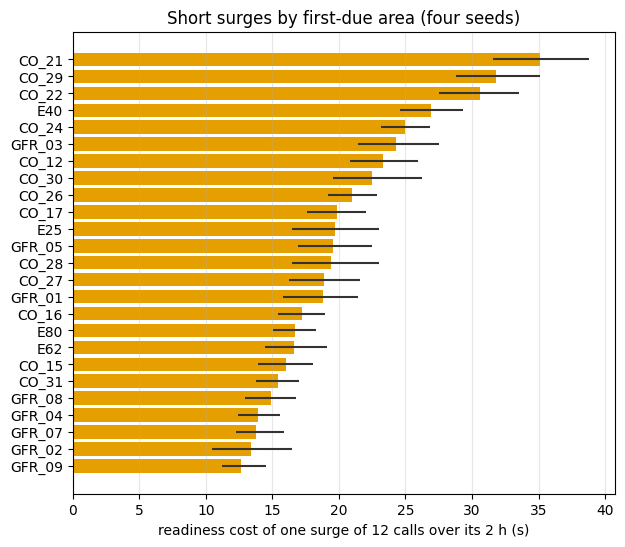

In [21]:
areas = pd.read_csv(OUTPUT_DIR / "scenario_surge_areas.csv", index_col=[0, 1])
print(areas.xs("all areas", level=1).round(2).to_string(), "\n")
by_area = areas.xs(12, level=0).drop(index="all areas").sort_values("readiness cost (s)")
fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(by_area.index, by_area["readiness cost (s)"], color=SIMULATED_COLOR,
        xerr=[by_area["readiness cost (s)"] - by_area["cost interval low"], by_area["cost interval high"] - by_area["readiness cost (s)"]],
        ecolor=RECORD_COLOR)
ax.set(xlabel="readiness cost of one surge of 12 calls over its 2 h (s)", title="Short surges by first-due area (four seeds)")
ax.grid(axis="x", alpha=0.3); plt.show()

## 7. The learned dispatcher's environment

The learned dispatcher decides every dispatch of a synthetic day. Each episode draws a training day, a condition and a
seed, simulates the six hours before the day under the protocol, then hands every decision of the day to the agent:
it picks one of the five closest eligible free engines. The reward charges each arrival at a call of the day its class
weight times the minutes from the call (later arrivals of a call at half weight), and a run released with no engine
its wait. Because almost half of the arrivals come after the next decision, a potential-based term moves each sent
run's estimated cost to the decision that sent it (the potential is minus the estimated cost of the runs on their
way); over a day it telescopes, so the ordering of policies is kept. These cells show the fitted inputs, one
decision's observation and the reward accounting.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().parents[1]                     # this notebook lives in code/dispatch_simulator/
sys.path.insert(0, str(PROJECT_ROOT / "code" / "dispatch_simulator"))
import environment, policies, rl_env, scenarios, train
import e2_small_system as e2

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
world = environment.build_world(verbose=False)
generator = scenarios.fit_generator(world, verbose=False)
rl = rl_env.fit_rl_inputs(world, verbose=True)

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


--- readiness cells (training non-fire calls per cell) (983, 12)
   cell_x  cell_y  calls_aid  calls_other  gfr_share        lon        lat  cell_gfr  weight_aid  weight_own      node       snap_m
0     339    3275          1            0        0.0 -82.654982  29.598021     False    0.000064    0.000000  84865896   252.552331
1     339    3277          0            2        0.0 -82.655907  29.621358     False    0.000000    0.000129  84865806    58.304544
2     339    3280          0            4        0.0 -82.656048  29.643792     False    0.000000    0.000257  97514109  1000.551629
3     340    3276          0            1        0.0 -82.644879  29.611932     False    0.000000    0.000064  84885468    38.695266
4     340    3277          0            1        0.0 -82.646634  29.620877     False    0.000000    0.000064  84779232   796.152603

training non-fire calls: 15,548 in 983 cells of 1000 m; with automatic aid 7,945, own agency only 7,603; cells mostly GFR 134; snap distance m

### 7.1 One decision: the observation, the candidates and the mask

In [2]:
env = rl_env.DispatchEnv(world, generator, rl, seed=3)
observation, info = env.reset()
print(f"episode: {info}; first decision of the day; {len(observation)} numbers")
call_labels = ["study fire", "high-acuity medical", "low-acuity", "other", "elevator", "brush", "arrived / 4",
               "responding / 4", "earliest remaining arrival / 10 min", "closest travel / 10 min", "lambda_F", "lambda_N"]
time_labels = ["sin hour", "cos hour", "weekend"]
system_labels = ["free engines share", "waiting runs / 10", "R_F / 10 min", "R_N / 10 min", "uncovered fire demand",
                 "uncovered non-fire demand", "estimated cost of runs on their way / 10"]
print(pd.Series(observation[:22], index=call_labels + time_labels + system_labels).round(3).to_string())
slot_labels = ["extra travel / 10 min", "minutes home / 30", "quint", "other agency", "10 x OC_F", "10 x OC_N",
               "uncovered fire rise", "uncovered non-fire rise"]
print(pd.DataFrame(observation[22:62].reshape(5, 8), index=[f"slot {i}: {e}" for i, e in enumerate(env.candidates)],
                   columns=slot_labels).round(3).to_string())
engines = pd.DataFrame(observation[62:].reshape(29, 5), index=rl["engine_position"].index,
                       columns=["free", "out", "on scene", "minutes on run / 120", "minutes home / 30"])
print(engines.head(8).round(3).to_string())
print(f"mask {env.action_masks()}; the protocol sends {env.protocol_engine} (slot {env.protocol_slot})")
env.close()

episode: {'condition': 'nominal', 'day': 147}; first decision of the day; 207 numbers
study fire                                  0.000
high-acuity medical                         1.000
low-acuity                                  0.000
other                                       0.000
elevator                                    0.000
brush                                       0.000
arrived / 4                                 0.000
responding / 4                              0.000
earliest remaining arrival / 10 min         0.000
closest travel / 10 min                     0.500
lambda_F                                    0.043
lambda_N                                    0.050
sin hour                                    0.087
cos hour                                    0.996
weekend                                     0.000
free engines share                          0.931
waiting runs / 10                           0.000
R_F / 10 min                                0.602
R_N / 10 min  

### 7.2 Reward accounting

The environment's return is checked against a count written separately from the run table: on a training day (the
episode ends at the first decision after midnight) and on a full day played to the end with the protocol's engine,
which must also equal the protocol simulated directly.

In [3]:
def independent_return(sim, scen, end_s):
    runs = scen["runs"]
    received = runs["call_received_at"]
    in_day = (received >= scen["day_start_s"]) & (received < scen["day_end_s"])
    stand_in = scen["dispatches"]["protocol"].eq(environment.OUT_OF_SERVICE_PROTOCOL).fillna(False).to_numpy()
    weight = scen["call_class"].map(lambda c: rl_env.CLASS_WEIGHTS[rl_env.CALL_CLASSES[c]])
    table = pd.DataFrame({"incident": runs["incident_id"], "arrived": sim["arrived_at"], "cleared": sim["cleared_at"],
                          "no_engine": sim["engine_id"].isna(), "received": received, "dispatch": runs["dispatched_at"],
                          "weight": weight})[in_day & ~stand_in]
    arrivals = table.dropna(subset=["arrived"]).sort_values("arrived", kind="stable")
    first = ~arrivals.duplicated("incident")
    total = -((arrivals["arrived"] - arrivals["received"]) / 600 * arrivals["weight"] * np.where(first, 1.0, rl_env.LATER_ARRIVAL_WEIGHT)).sum()
    first_arrival = arrivals[first].set_index("incident")["arrived"]
    for _, row in table[table["no_engine"] & (table["cleared"] < end_s)].iterrows():
        if not first_arrival.get(row["incident"], np.inf) <= row["cleared"]:
            total -= row["weight"] * (row["cleared"] - row["dispatch"]) / 600
    return total

env = rl_env.DispatchEnv(world, generator, rl, seed=11)
for full_day in [False, True]:
    observation, info = env.reset(options={"full_day": full_day})
    while True:
        observation, reward, terminated, truncated, step_info = env.step(env.protocol_slot or 0)
        if terminated or truncated:
            break
    line = (f"{'full day' if full_day else 'training day'} ({info['condition']}, day {info['day']}): {step_info['decisions']} decisions, "
            f"environment {step_info['unshaped_return']:.3f}, independent count {independent_return(env.simulated, env.scenario, step_info['end_s']):.3f}")
    if full_day:
        prepared = rl_env.prepare_scenario(world, rl, env.scenario)
        direct = environment.simulate(world, env.scenario, policies.closest_engine, verbose=False)
        line += f", protocol simulated directly {rl_env.accrued_reward(prepared, direct, rl_env.new_tally(prepared)):.3f}"
    print(line)
env.close()

training day (more calls, day 25): 113 decisions, environment -114.140, independent count -114.140


full day (nominal, day 109): 104 decisions, environment -165.563, independent count -165.563, protocol simulated directly -165.563


## 8. The learnability gate

Before training on the full simulator, the agent must find a known optimum: three stations with one engine each,
medical calls at three places and fire calls at a fourth. Value iteration gives the exact optimal policy; the agent's
greedy policy is evaluated with the same equations. The first agent (400,000 decisions, 10 epochs per update) learned
only the closest-engine rule at fire weight 8; an ASHA search over the PPO settings, scored by the exact share of the
improvement captured, found settings that pass. The gate re-trains with them on fresh seeds, without and with the
readiness shaping term; the comparison decides whether the full environment trains with shaping.

In [4]:
for fire_weight in e2.FIRE_WEIGHTS:
    optimal_values, optimal_ranks = e2.solve(fire_weight)
    protocol_values, _ = e2.solve(fire_weight, np.zeros((8, e2.N_CALL_TYPES), dtype=int))
    optimum, protocol = e2.start_value(optimal_values), e2.start_value(protocol_values)
    print(f"fire weight {fire_weight}: protocol {protocol:.4f}, optimum {optimum:.4f}, improvement {100 * (optimum - protocol) / -protocol:.2f}% of the protocol's cost")
search = pd.read_csv(train.MODEL_DIR / "e2_search_trials.csv")
columns = ["number", "value", "state"] + [c for c in search.columns if c.startswith("params_")]
print(search[columns].sort_values("value", ascending=False).head(10).round(5).to_string(index=False))

fire weight 2.0: protocol -16.1327, optimum -16.1327, improvement 0.00% of the protocol's cost
fire weight 8.0: protocol -27.2720, optimum -26.9399, improvement 1.22% of the protocol's cost


fire weight 32.0: protocol -71.8293, optimum -66.8668, improvement 6.91% of the protocol's cost
 number   value    state  params_batch_size  params_clip_range  params_ent_coef  params_gae_lambda  params_learning_rate  params_n_epochs  params_n_steps  params_vf_coef  params_width
     19 1.00000 COMPLETE               2048                0.2          0.00092               0.80               0.00039               20             512             0.5           128
     14 1.00000 COMPLETE               4096                0.1          0.00161               0.95               0.00061               20             512             0.5           128
      5 1.00000 COMPLETE               1024                0.1          0.00046               0.80               0.00012               20             512             1.0           256
     10 1.00000 COMPLETE               2048                0.2          0.00256               0.95               0.00029               20             512             0.

In [5]:
best = json.loads((train.MODEL_DIR / "e2_search_best_settings.json").read_text())
gate = train.e2_gate(best)

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.che

--- fire weight 2.0, seed 101: decision states where the optimum or the agent leaves the closest engine
Empty DataFrame
Columns: [optimal rank, agent rank, agent probability of optimal rank]
Index: []

--- fire weight 2.0, seed 102: decision states where the optimum or the agent leaves the closest engine
Empty DataFrame
Columns: [optimal rank, agent rank, agent probability of optimal rank]
Index: []

--- fire weight 8.0, seed 101: decision states where the optimum or the agent leaves the closest engine
                         optimal rank  agent rank  agent probability of optimal rank
busy A,B,C call                                                                     
000        medical at M             1           1                              0.977
100        medical at M             1           1                              0.836
010        medical at B             1           1                              0.846

--- fire weight 8.0, seed 102: decision states where the optimum o

In [6]:
gate_shaped = train.e2_gate(best, shaping=True)

/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.13/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.che

--- fire weight 2.0, seed 101: decision states where the optimum or the agent leaves the closest engine
Empty DataFrame
Columns: [optimal rank, agent rank, agent probability of optimal rank]
Index: []

--- fire weight 2.0, seed 102: decision states where the optimum or the agent leaves the closest engine
Empty DataFrame
Columns: [optimal rank, agent rank, agent probability of optimal rank]
Index: []

--- fire weight 8.0, seed 101: decision states where the optimum or the agent leaves the closest engine
                         optimal rank  agent rank  agent probability of optimal rank
busy A,B,C call                                                                     
000        medical at M             1           1                              0.981
100        medical at M             1           1                              0.762
010        medical at B             1           1                              0.868

--- fire weight 8.0, seed 102: decision states where the optimum o

## 9. Reward timing

Under arrival-event accounting an engine's cost is charged when it arrives. The next cell counts, on synthetic days
under the protocol, how often that happens after the next decision. The comparison below it trains the same settings,
seed and warm start with and without the term that moves each run's estimated cost to its dispatch.

In [7]:
rng = np.random.default_rng(5)
later = total = 0
for _ in range(10):
    scenario = rl_env.sample_scenario(world, generator, rng)
    decisions = []
    def recording(world_, scenario_, run, available, travel_s, context=None):
        engine = policies.closest_engine(world_, scenario_, run, available, travel_s)
        if context["now"] >= scenario["day_start_s"] and engine is not None:
            decisions.append((context["now"], run.name))
        return engine
    simulated = environment.simulate(world, scenario, recording, verbose=False)
    times = [t for t, _ in decisions]
    for i, (t, row) in enumerate(decisions):
        arrived = simulated.at[row, "arrived_at"]
        following = [u for u in times[i + 1:] if u > t]
        if np.isnan(arrived) or not following:
            continue
        total += 1
        later += arrived > following[0]
print(f"runs that arrive: {total}; arriving after the next decision: {later} ({later / total:.1%})")

runs that arrive: 1124; arriving after the next decision: 495 (44.0%)


on, seed 3000 [[0.0, -0.031, nan], [2048.0, -0.031, 0.008], [202752.0, -0.061, 0.028], [403456.0, 0.102, 0.105]]
off, seed 3000 [[0.0, -0.031, nan], [2048.0, -0.031, 0.008], [202752.0, -0.099, 0.016], [403456.0, -1.882, 0.111]]
on, seed 4000 [[0.0, -0.03, nan, nan], [2048.0, -0.03, -0.16, 0.008], [202752.0, 0.457, 0.327, 0.034], [403456.0, -0.598, -0.728, 0.06]]
off, seed 4000 [[0.0, -0.03, nan, nan], [2048.0, -0.03, -0.16, 0.008], [202752.0, -0.487, -0.617, 0.024], [403456.0, 0.17, 0.04, 0.059]]


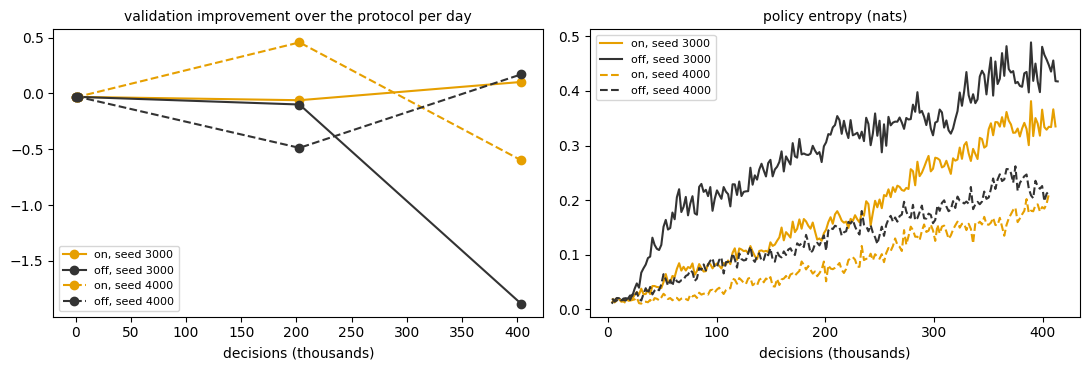

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
runs = [("transfer_on", "#E69F00", "-", "on, seed 3000"), ("transfer_off", "#333333", "-", "off, seed 3000"),
        ("transfer_on_seed4000", "#E69F00", "--", "on, seed 4000"), ("transfer_off_seed4000", "#333333", "--", "off, seed 4000")]
for name, color, style, label in runs:
    progress = pd.read_csv(train.MODEL_DIR / "reward_timing" / name / "progress.csv")
    validation = progress.dropna(subset=["eval/improvement_mean"])
    axes[0].plot(validation["time/total_timesteps"] / 1e3, validation["eval/improvement_mean"], marker="o", color=color, linestyle=style, label=label)
    rows = progress.dropna(subset=["train/entropy_loss"])
    axes[1].plot(rows["time/total_timesteps"] / 1e3, -rows["train/entropy_loss"], color=color, linestyle=style, label=label)
    columns = [c for c in ["time/total_timesteps", "eval/improvement_mean", "eval/improvement_over_closest_mean", "eval/deviation_share"] if c in validation.columns]
    print(label, validation[columns].round(3).values.tolist())
axes[0].set_title("validation improvement over the protocol per day", fontsize=10); axes[1].set_title("policy entropy (nats)", fontsize=10)
for ax in axes:
    ax.set_xlabel("decisions (thousands)"); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 10. Training the dispatcher

An ASHA search compared PPO settings on the full environment by the improvement over the protocol on twelve fixed
validation days (held-out seeds of the training distribution). Every surviving setting reached the same score as the
closest engine without the quint rule, so the search stopped early and trial 3's settings (the smallest network and
the fewest epochs among the tied, no warm start) trained the final model. The accepted run is a fresh one whose
acceptance rule was fixed before it started: 6M decisions, seed 600,000. Its acceptance reads the training signals:
the training reward rises from the untrained policy's level (measured on 100 episodes before any update) and levels
off, the validation improvement rises and levels off, the critic's explained variance stays positive and does not
fall, the approx KL stays small, and the policy entropy holds clear preferences without drifting up.

In [3]:
trials = pd.read_csv(train.MODEL_DIR / "dispatch_search_trials.csv")
columns = ["number", "state"] + [c for c in trials.columns if c.startswith("rung_")] + [c for c in trials.columns if c.startswith("params_")]
print(trials[columns].round(5).to_string(index=False))
print("the search was stopped after six trials: every surviving setting reached the closest engine's score, +0.1299661991 per day")

 number   state  rung_401408  rung_1204224  params_learning_rate  params_n_steps  params_batch_size  params_n_epochs  params_gae_lambda  params_ent_coef  params_clip_range  params_vf_coef  params_width  params_bc_epochs
      0  PRUNED      0.03504           NaN               0.00030            1024               4096               10               0.95          0.01000                0.2             0.5           128                20
      1 RUNNING      0.12997       0.12997               0.00030            1024               4096               10               0.95          0.01000                0.2             0.5           128                 0
      2  PRUNED      0.10249           NaN               0.00012             512               1024               20               0.80          0.00046                0.1             1.0           256                20
      3 RUNNING      0.12997           NaN               0.00027             512               1024                5    

settings: {'learning_rate': 0.00027289457495676024, 'n_steps': 256, 'batch_size': 1024, 'n_epochs': 5, 'gae_lambda': 0.5, 'ent_coef': 0.00026570618462824, 'clip_range': 0.2, 'vf_coef': 1.0, 'width': 128, 'bc_epochs': 0}
untrained policy: mean episode reward -146.923 over 100 episodes (seed 700000)


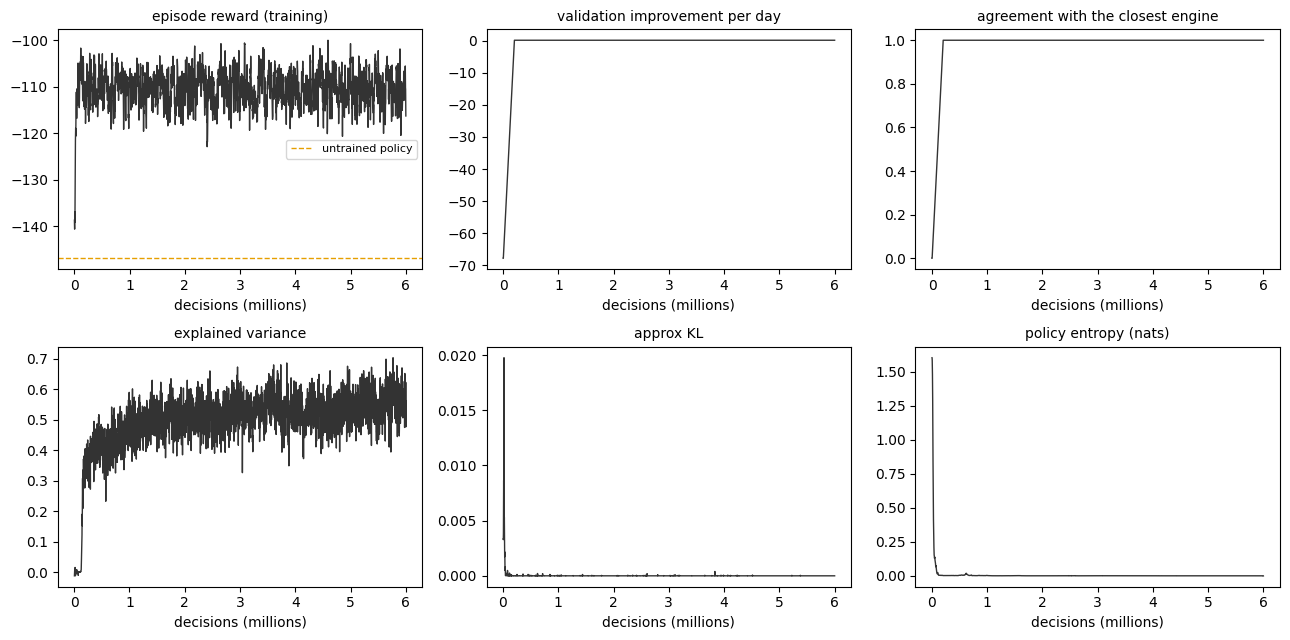

                                                                 value threshold passes
training reward rises (late minus untrained)                 36.384248       > 0   True
training reward converged (late trend change / rise)          0.024071     < 0.1   True
training reward plateau (late block range / rise)              0.01709     < 0.1   True
validation improvement rises (last three minus first)        67.928734       > 0   True
validation improvement converged (late trend change / rise)        0.0     < 0.1   True
explained variance (late mean)                                0.543074       > 0   True
explained variance not falling (late minus middle)            0.015457   > -0.05   True
approx KL (largest, second half)                              0.000394   <= 0.05   True
entropy late (nats)                                           0.000055   < 0.805   True
entropy late trend change (nats)                              -0.00005    < 0.05   True


In [4]:
run_dir = train.MODEL_DIR / "final_preregistered"
progress = pd.read_csv(run_dir / "progress.csv")
initial = json.loads((run_dir / "initial_reward.json").read_text())
print(f"settings: {json.loads((run_dir / 'settings.json').read_text())}")
print(f"untrained policy: mean episode reward {initial['initial_episode_reward']:.3f} over {initial['episodes']} episodes (seed {initial['seed']})")
signals = [("rollout/ep_rew_mean", "episode reward (training)"), ("eval/improvement_mean", "validation improvement per day"),
           ("eval/closest_agreement", "agreement with the closest engine"), ("train/explained_variance", "explained variance"),
           ("train/approx_kl", "approx KL"), ("train/entropy_loss", "policy entropy (nats)")]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, (column, title) in zip(axes.ravel(), signals):
    data = progress[["time/total_timesteps", column]].dropna()
    values = -data[column] if column == "train/entropy_loss" else data[column]
    ax.plot(data["time/total_timesteps"] / 1e6, values, color="#333333", linewidth=1)
    if column == "rollout/ep_rew_mean":
        ax.axhline(initial["initial_episode_reward"], color="#E69F00", linewidth=1, linestyle="--", label="untrained policy")
        ax.legend(fontsize=8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("decisions (millions)")
fig.tight_layout()
plt.show()
print(train.acceptance(progress, initial["initial_episode_reward"]).to_string())

In [5]:
validation = pd.read_csv(run_dir / "validation_days.csv")
print(validation.round(3).to_string(index=False))
print(f"validation panel: improvement over the protocol {validation['improvement'].mean():.4f} per day, over the closest engine "
      f"{validation['improvement over closest'].mean():.4f}, agreement with the closest engine {validation['closest agreement'].mean():.4f}")

     condition  day  protocol return  closest return  agent return  improvement  improvement over closest  deviation share  closest agreement
    large fire   21         -107.462        -107.530      -107.530       -0.068                       0.0            0.124                1.0
       nominal   97          -49.965         -49.950       -49.950        0.015                       0.0            0.020                1.0
closed station  110         -103.154        -103.149      -103.149        0.005                       0.0            0.026                1.0
       nominal   70          -54.540         -54.540       -54.540       -0.000                       0.0            0.011                1.0
         surge   70         -121.167        -119.812      -119.812        1.355                       0.0            0.009                1.0
    more calls  101         -157.360        -157.355      -157.355        0.004                       0.0            0.015                1.0
   eng

The same frozen model on an independent panel of twelve days, drawn from a seed that neither training nor the search used.

In [6]:
from sb3_contrib import MaskablePPO
model = MaskablePPO.load(run_dir / "model")
panel = train.Evaluator(days=train.VALIDATION_DAYS, seed=train.VALIDATION_SEED + 1).compare(model)
print(panel.round(3).to_string(index=False))
print(f"independent panel: improvement over the protocol {panel['improvement'].mean():.4f} per day, over the closest engine "
      f"{panel['improvement over closest'].mean():.4f}, agreement with the closest engine {panel['closest agreement'].mean():.4f}")

     condition  day  protocol return  closest return  agent return  improvement  improvement over closest  deviation share  closest agreement
         surge  156          -89.111         -89.111       -89.111       -0.000                       0.0            0.008                1.0
    more calls    2         -114.932        -114.887      -114.887        0.045                       0.0            0.114                1.0
    more calls   49         -136.091        -135.897      -135.897        0.194                       0.0            0.162                1.0
         surge   52         -124.100        -124.010      -124.010        0.090                       0.0            0.093                1.0
       nominal   48         -100.778        -100.569      -100.569        0.209                       0.0            0.127                1.0
   engines out   16         -145.987        -145.988      -145.988       -0.002                       0.0            0.036                1.0
closed

The first final run (same settings, seed 500,000) reached the same policy. Its acceptance window was changed while it
ran, so it is shown here only as a second seed, not as the accepted run.

In [7]:
first = pd.read_csv(train.MODEL_DIR / "final" / "progress.csv")
evaluations = first.dropna(subset=["eval/improvement_mean"])
print(f"first final run: {int(first['time/total_timesteps'].max()):,} decisions; validation from 202,752 decisions on: "
      f"{sorted(evaluations['eval/improvement_mean'].iloc[2:].round(7).unique())} per day, agreement "
      f"{sorted(evaluations['eval/closest_agreement'].iloc[2:].unique())}")

first final run: 6,000,640 decisions; validation from 202,752 decisions on: [np.float64(0.1299662)] per day, agreement [np.float64(1.0)]


## 11. Output check

The comparison script checks every table `main.py` wrote against the tables written before the code was reorganized:
byte for byte where only the file name changed, and cell by cell where labels were renamed or rows and columns of the
deleted versions were removed.

In [22]:
check = subprocess.run([sys.executable, str(PROJECT_ROOT / ".aris" / "traces" / "refactor" / "2026-11-14_run01" / "compare_outputs.py")],
                       capture_output=True, text=True, cwd=PROJECT_ROOT)
print(check.stdout[-6000:], check.stderr[-2000:])

nario_room.csv                  scenario_room.csv                                                                                                                           bytes       True
    scenario_policy_comparison.csv     scenario_policy_comparison.csv                                                                                                                           bytes       True
               scenario_surges.csv                scenario_surges.csv                                                                                                                           bytes       True
          scenario_surge_areas.csv           scenario_surge_areas.csv                                                                                                                           bytes       True
             fit_travel_spread.csv              m01_travel_spread.csv                                                                                                                   